# Partie 3 (Q7) : comparaison équitable RDD / DataFrame / SQL

Protocole, identique pour toutes les variantes :
- **même calcul** : lecture du fichier dans MinIO, filtre `COMPLETED`, dédoublonnage par `tx_id`, puis somme et nombre par ville, et `collect()` ;
- **aucun cache** : chaque exécution relit la source ;
- **1 exécution d'échauffement** (ignorée : JIT de la JVM, connexions S3, démarrage des workers Python), puis **5 exécutions mesurées** ;
- on retient le **minimum** et la **médiane**, sur la même session et le même cluster (2 Workers × 2 cœurs).

In [1]:
import json, time, statistics
from common import get_spark, LAKE
from pyspark.sql import functions as F
from schemas import tx_schema

spark = get_spark("SahlPay-P3-Benchmark")
sc = spark.sparkContext
for _ in range(30):
    if sc._jsc.sc().getExecutorMemoryStatus().size() >= 3:
        break
    time.sleep(1)
print("Spark", spark.version, "| cœurs:", sc.defaultParallelism)

SRC = f"{LAKE}/bronze/history/transactions_history.jsonl"
SILVER = f"{LAKE}/silver/transactions_history/"

https://repos.spark-packages.org added as a remote repository with the name: repo-1
Ivy Default Cache set to: /tmp/ivy/cache
The jars for the packages stored in: /tmp/ivy/jars
org.apache.hadoop#hadoop-aws added as a dependency
com.amazonaws#aws-java-sdk-bundle added as a dependency
org.apache.spark#spark-sql-kafka-0-10_2.12 added as a dependency
io.delta#delta-spark_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-8428cab7-4a73-4ab3-a009-483077ea0df8;1.0
	confs: [default]


:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found org.apache.hadoop#hadoop-aws;3.3.4 in central
	found com.amazonaws#aws-java-sdk-bundle;1.12.262 in central
	found org.wildfly.openssl#wildfly-openssl;1.0.7.Final in central
	found org.apache.spark#spark-sql-kafka-0-10_2.12;3.5.1 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.5.1 in central
	found org.apache.kafka#kafka-clients;3.4.1 in central
	found org.lz4#lz4-java;1.8.0 in central


	found org.xerial.snappy#snappy-java;1.1.10.3 in central
	found org.slf4j#slf4j-api;2.0.7 in central
	found org.apache.hadoop#hadoop-client-runtime;3.3.4 in central
	found org.apache.hadoop#hadoop-client-api;3.3.4 in central
	found commons-logging#commons-logging;1.1.3 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.apache.commons#commons-pool2;2.11.1 in central
	found io.delta#delta-spark_2.12;3.2.0 in central
	found io.delta#delta-storage;3.2.0 in central
	found org.antlr#antlr4-runtime;4.9.3 in central


:: resolution report :: resolve 555ms :: artifacts dl 46ms
	:: modules in use:
	com.amazonaws#aws-java-sdk-bundle;1.12.262 from central in [default]
	com.google.code.findbugs#jsr305;3.0.0 from central in [default]
	commons-logging#commons-logging;1.1.3 from central in [default]
	io.delta#delta-spark_2.12;3.2.0 from central in [default]
	io.delta#delta-storage;3.2.0 from central in [default]
	org.antlr#antlr4-runtime;4.9.3 from central in [default]
	org.apache.commons#commons-pool2;2.11.1 from central in [default]
	org.apache.hadoop#hadoop-aws;3.3.4 from central in [default]
	org.apache.hadoop#hadoop-client-api;3.3.4 from central in [default]
	org.apache.hadoop#hadoop-client-runtime;3.3.4 from central in [default]
	org.apache.kafka#kafka-clients;3.4.1 from central in [default]
	org.apache.spark#spark-sql-kafka-0-10_2.12;3.5.1 from central in [default]
	org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.5.1 from central in [default]
	org.lz4#lz4-java;1.8.0 from central in [default]


26/11/24 17:10:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.1 | cœurs: 4


In [2]:
def run_rdd():
    return (sc.textFile(SRC)
              .map(json.loads)
              .filter(lambda e: e["status"] == "COMPLETED")
              .map(lambda e: (e["tx_id"], e))
              .reduceByKey(lambda a, b: a)
              .map(lambda kv: (kv[1]["city"], (kv[1]["amount_mad"], 1)))
              .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
              .collect())

def run_df():
    return (spark.read.schema(tx_schema).json(SRC)
              .filter("status = 'COMPLETED'")
              .dropDuplicates(["tx_id"])
              .groupBy("city").agg(F.sum("amount_mad").alias("total"), F.count("*").alias("nb"))
              .collect())

def run_sql():
    spark.read.schema(tx_schema).json(SRC).createOrReplaceTempView("tx_bench")
    return spark.sql("""
        SELECT city, SUM(amount_mad) AS total, COUNT(*) AS nb
        FROM (SELECT tx_id, FIRST(city) AS city, FIRST(amount_mad) AS amount_mad
              FROM tx_bench WHERE status = 'COMPLETED' GROUP BY tx_id)
        GROUP BY city""").collect()

def run_df_parquet():
    # même calcul, mais sur la couche Silver (Parquet colonnaire, partitionné par city)
    return (spark.read.parquet(SILVER)
              .filter("status = 'COMPLETED'")
              .dropDuplicates(["tx_id"])
              .groupBy("city").agg(F.sum("amount_mad").alias("total"), F.count("*").alias("nb"))
              .collect())

def norm(rows):
    # résultat comparable quelle que soit l'API : {ville: (total arrondi, nombre)}
    out = {}
    for r in rows:
        if isinstance(r, tuple) and len(r) == 2 and isinstance(r[1], tuple):   # RDD
            out[r[0]] = (round(r[1][0], 2), r[1][1])
        else:
            out[r["city"]] = (round(r["total"], 2), r["nb"])
    return out

In [3]:
variants = [("RDD (JSON, lambdas Python)", run_rdd),
            ("DataFrame (JSON)", run_df),
            ("Spark SQL (JSON)", run_sql),
            ("DataFrame (Parquet Silver)", run_df_parquet)]

results, reference = {}, None
for name, fn in variants:
    res = fn()                                   # échauffement (ignoré)
    if reference is None:
        reference = norm(res)
    assert norm(res) == reference, f"{name} : résultat différent !"
    times = []
    for _ in range(5):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    results[name] = times
    print(f"{name:<28} min {min(times):5.2f} s | médiane {statistics.median(times):5.2f} s | "
          + ", ".join(f"{t:.2f}" for t in times))
print("\nLes 4 variantes donnent exactement le même résultat.")

26/11/24 17:10:22 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


RDD (JSON, lambdas Python)   min  0.89 s | médiane  0.98 s | 3.60, 0.89, 0.90, 1.20, 0.98


DataFrame (JSON)             min  1.11 s | médiane  1.17 s | 2.60, 1.17, 1.11, 1.14, 1.75


Spark SQL (JSON)             min  0.74 s | médiane  0.85 s | 0.85, 1.11, 0.74, 0.80, 1.06


DataFrame (Parquet Silver)   min  1.00 s | médiane  1.16 s | 1.16, 1.04, 2.02, 1.40, 1.00

Les 4 variantes donnent exactement le même résultat.


In [4]:
import pandas as pd
base = statistics.median(results["RDD (JSON, lambdas Python)"])
table = pd.DataFrame([{"Variante": k,
                       "min (s)": round(min(v), 2),
                       "médiane (s)": round(statistics.median(v), 2),
                       "accélération vs RDD": f"x{base / statistics.median(v):.1f}"}
                      for k, v in results.items()])
table

,Variante,min (s),médiane (s),accélération vs RDD
0,"RDD (JSON, lambdas Python)",0.89,0.98,x1.0
1,DataFrame (JSON),1.11,1.17,x0.8
2,Spark SQL (JSON),0.74,0.85,x1.1
3,DataFrame (Parquet Silver),1.00,1.16,x0.8


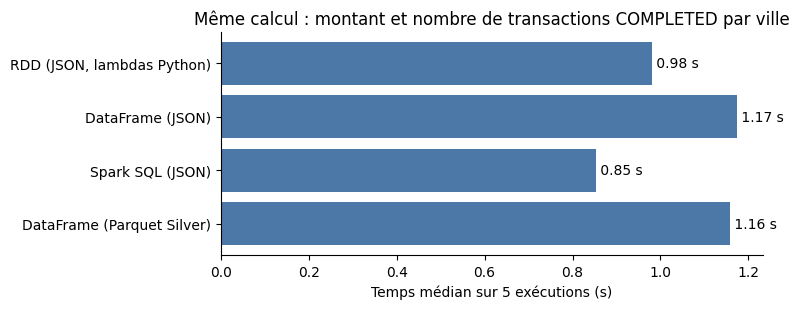

In [5]:
import matplotlib.pyplot as plt
names = list(results)
med = [statistics.median(results[n]) for n in names]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(names[::-1], med[::-1], color="#4C78A8")
for y, v in enumerate(med[::-1]):
    ax.text(v, y, f" {v:.2f} s", va="center")
ax.set_xlabel("Temps médian sur 5 exécutions (s)")
ax.set_title("Même calcul : montant et nombre de transactions COMPLETED par ville")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("/home/work/work/benchmark_rdd_df_sql.png", dpi=150)
plt.show()

## Passage à l'échelle : ×20 (1 000 000 d'événements, environ 220 Mo)
Avec 50 000 lignes, toutes les variantes prennent environ 1 s : le **coût fixe** (planification des jobs, lancement des tâches, accès S3) domine.
On duplique le jeu 20 fois, avec des `tx_id` distincts par copie pour que le dédoublonnage reste significatif, et on refait **exactement** les mêmes mesures.

In [6]:
raw = spark.read.text(SRC)
big = None
for k in range(20):
    part = raw.select(F.regexp_replace("value", '"TX-', f'"TX-{k:02d}').alias("value"))
    big = part if big is None else big.unionByName(part)
SRC_X20 = f"{LAKE}/bronze/history_x20/"
big.repartition(8).write.mode("overwrite").text(SRC_X20)
SILVER_X20 = f"{LAKE}/silver/transactions_history_x20/"
spark.read.schema(tx_schema).json(SRC_X20).dropDuplicates(["tx_id", "status"])      .write.mode("overwrite").partitionBy("city").parquet(SILVER_X20)
print("Événements x20 :", spark.read.text(SRC_X20).count())

26/11/24 17:11:52 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.


Événements x20 : 1000000


In [7]:
SRC, SILVER = SRC_X20, SILVER_X20          # les fonctions run_* lisent ces variables globales
results_x20, reference = {}, None
for name, fn in variants:
    res = fn()                             # échauffement (ignoré)
    if reference is None:
        reference = norm(res)
    assert norm(res) == reference, f"{name} : résultat différent !"
    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    results_x20[name] = times
    print(f"{name:<28} min {min(times):6.2f} s | médiane {statistics.median(times):6.2f} s | "
          + ", ".join(f"{t:.2f}" for t in times))

RDD (JSON, lambdas Python)   min   3.90 s | médiane   4.23 s | 4.23, 4.76, 3.90


DataFrame (JSON)             min   1.56 s | médiane   2.00 s | 1.56, 2.00, 2.17


Spark SQL (JSON)             min   1.67 s | médiane   1.71 s | 1.71, 1.67, 1.71


DataFrame (Parquet Silver)   min   1.66 s | médiane   1.68 s | 1.66, 2.02, 1.68


In [8]:
base = statistics.median(results["RDD (JSON, lambdas Python)"])
base20 = statistics.median(results_x20["RDD (JSON, lambdas Python)"])
table = pd.DataFrame([{"Variante": k,
                       "50 k évts : médiane (s)": round(statistics.median(results[k]), 2),
                       "1 M évts : médiane (s)": round(statistics.median(results_x20[k]), 2),
                       "1 M : accélération vs RDD": f"x{base20 / statistics.median(results_x20[k]):.1f}"}
                      for k in results])
table

,Variante,50 k évts : médiane (s),1 M évts : médiane (s),1 M : accélération vs RDD
0,"RDD (JSON, lambdas Python)",0.98,4.23,x1.0
1,DataFrame (JSON),1.17,2.00,x2.1
2,Spark SQL (JSON),0.85,1.71,x2.5
3,DataFrame (Parquet Silver),1.16,1.68,x2.5


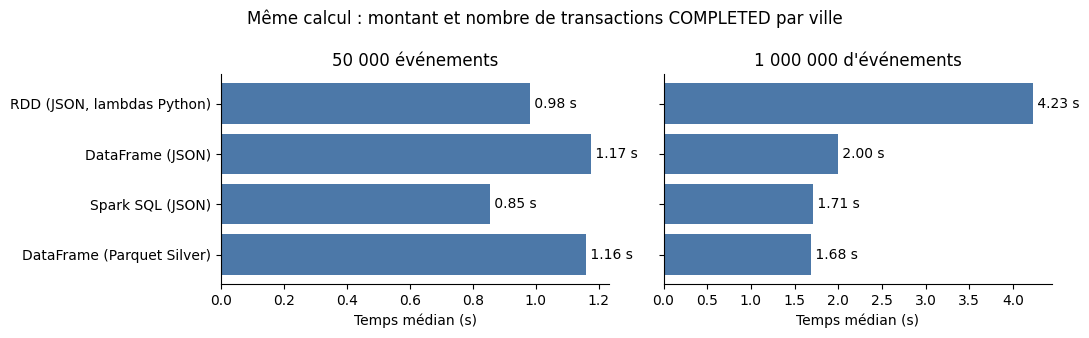

In [9]:
import numpy as np
names = list(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, res, title in [(axes[0], results, "50 000 événements"), (axes[1], results_x20, "1 000 000 d'événements")]:
    med = [statistics.median(res[n]) for n in names]
    ax.barh(names[::-1], med[::-1], color="#4C78A8")
    for y, v in enumerate(med[::-1]):
        ax.text(v, y, f" {v:.2f} s", va="center")
    ax.set_title(title); ax.set_xlabel("Temps médian (s)")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Même calcul : montant et nombre de transactions COMPLETED par ville")
plt.tight_layout()
plt.savefig("/home/work/work/benchmark_rdd_df_sql.png", dpi=150)
plt.show()

In [10]:
# Plans : DataFrame et SQL produisent le même plan physique (même optimiseur Catalyst)
spark.read.schema(tx_schema).json(SRC).filter("status = 'COMPLETED'").dropDuplicates(["tx_id"]) \
     .groupBy("city").agg(F.sum("amount_mad"), F.count("*")).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[city#2798], functions=[sum(amount_mad#2804), count(1)])
   +- Exchange hashpartitioning(city#2798, 8), ENSURE_REQUIREMENTS, [plan_id=4387]
      +- HashAggregate(keys=[city#2798], functions=[partial_sum(amount_mad#2804), partial_count(1)])
         +- SortAggregate(key=[tx_id#2751], functions=[first(city#2756, false), first(amount_mad#2759, false)])
            +- Sort [tx_id#2751 ASC NULLS FIRST], false, 0
               +- Exchange hashpartitioning(tx_id#2751, 8), ENSURE_REQUIREMENTS, [plan_id=4382]
                  +- SortAggregate(key=[tx_id#2751], functions=[partial_first(city#2756, false), partial_first(amount_mad#2759, false)])
                     +- Sort [tx_id#2751 ASC NULLS FIRST], false, 0
                        +- Project [tx_id#2751, city#2756, amount_mad#2759]
                           +- Filter (isnotnull(status#2758) AND (status#2758 = COMPLETED))
                              +- FileScan

In [11]:
spark.stop()